# 🎶 Music Generation with Transformers — Modified

In this notebook we train a Transformer to generate music in the style of the Bach cello suites, as in `transformer.ipynb`, but with changes aimed at **better training behaviour, better generated music and much faster generation**.

| # | Area | `transformer.ipynb` (baseline) | `transformer-modified.ipynb` |
|---|------|-------------------------------|------------------------------|
| 1 | Block layout | Post-LayerNorm, 1 block | **Pre-LayerNorm**, **2 stacked blocks** |
| 2 | Feed-forward activation | ReLU | **GELU** |
| 3 | Regularisation | Dropout in block only | Dropout in block **and on the embeddings**, **AdamW** weight decay |
| 4 | Note/duration mixing | Concatenate only | Concatenate + learned **fusion projection** (Dense + LayerNorm) |
| 5 | Evaluation | training loss only | **held-out validation split** (whole movements), early stopping, LR reduction |
| 6 | Data pipeline | tokenise inside `tf.data.map` every epoch | **tokenise once**, cache int arrays, shuffle at sequence level, prefetch |
| 7 | Decoding | pure `p**(1/T)` sampling, rejection loops for `[UNK]` | log-space temperature, **top-k + nucleus (top-p)**, **repetition penalty**, `[UNK]`/padding masked, duration chosen conditionally on the note |
| 8 | Inference speed | `model.predict()` **twice** per token (+ builds a new Keras model per call) | one compiled `tf.function`, **one** forward pass per token |
| 9 | Output normalisation | none (Post-LN) | **final LayerNorm** before the output heads (needed by Pre-LN) |
| 10 | Training data | 36 movements, as parsed | **random transposition augmentation** (-5 to +6 semitones, every epoch) |

Everything is measured in the cells below and written to `output/modified_metrics.json`.

In [38]:
# Setup for Google Colab and local environments
import os
import sys

# Python 3.12+ compatibility shim for 'imp' (used by legacy autoreload)
if "imp" not in sys.modules:
    try:
        import imp
    except ImportError:
        import importlib
        import types

        _imp = types.ModuleType("imp")
        _imp.reload = importlib.reload
        sys.modules["imp"] = _imp

# 1. If running in Google Colab, clone the repository and navigate into it
if "google.colab" in sys.modules:
    if os.path.exists("/content"):
        %cd /content
    if not os.path.exists("Generative_Deep_Learning_2nd_Edition"):
        !git clone https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition.git
    %cd /content/Generative_Deep_Learning_2nd_Edition
    if os.path.abspath(".") not in sys.path:
        sys.path.append(os.path.abspath("."))

# 2. Add repository root to sys.path if running locally outside repository root
repo_root = None
for candidate in [
    os.path.abspath(os.path.join(os.getcwd(), "../../..")),
    os.path.abspath(os.getcwd()),
    os.path.abspath("/content/Generative_Deep_Learning_2nd_Edition"),
    "/app",
]:
    if os.path.exists(os.path.join(candidate, "notebooks")):
        repo_root = candidate
        break
if repo_root is None:
    repo_root = os.path.abspath(os.path.join(os.getcwd(), "../../.."))

if repo_root not in sys.path:
    sys.path.append(repo_root)

# 3. Add notebook directory to sys.path for local module imports (transformer_utils)
notebook_dir = os.path.join(repo_root, "notebooks", "11_music", "01_transformer")
if os.path.exists(notebook_dir) and notebook_dir not in sys.path:
    sys.path.append(notebook_dir)


/content
/content/Generative_Deep_Learning_2nd_Edition


In [39]:
# Python 3.12+ compatibility shim for 'imp' (used by legacy autoreload)
import sys
if "imp" not in sys.modules:
    try:
        import imp
    except ImportError:
        import importlib
        import types

        _imp = types.ModuleType("imp")
        _imp.reload = importlib.reload
        sys.modules["imp"] = _imp

# Enable autoreload if available and supported
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except Exception:
    pass

import os
import glob
import json
import numpy as np
import time
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, losses, callbacks

try:
    import music21
except ImportError:
    get_ipython().system("pip install music21")
    import music21

from transformer_utils import (
    parse_midi_files,
    load_parsed_files,
    get_midi_note,
    SinePositionEncoding,
)

# The helpers below were added locally to transformer_utils.py. On Colab the
# notebook clones the *upstream* repo, whose transformer_utils.py does not have
# them, so fall back to equivalent definitions here.
try:
    from transformer_utils import (
        split_sequences,
        tokenize_sequences,
        encode_with,
        generation_metrics,
    )
except ImportError:
    from collections import Counter

    def split_sequences(notes, durations, seq_len, val_frac=0.1):
        """Hold out the final `val_frac` of the (file-ordered) windows, leaving a
        gap of `seq_len` windows so no validation window shares a token with training."""
        n = len(notes)
        cut = int(n * (1 - val_frac))
        gap = seq_len
        return (
            (notes[:cut], durations[:cut]),
            (notes[cut + gap :], durations[cut + gap :]),
        )

    def tokenize_sequences(notes, durations):
        """Fit one TextVectorization layer per stream -> [(vec, vocab), (vec, vocab)]."""
        out = []
        for elements in (notes, durations):
            vec = tf.keras.layers.TextVectorization(standardize=None, output_mode="int")
            vec.adapt(tf.data.Dataset.from_tensor_slices(elements).batch(1024))
            out.append((vec, vec.get_vocabulary()))
        return out

    def encode_with(vec, elements):
        return vec(tf.constant(elements)).numpy().astype(np.int32)

    def generation_metrics(generated_notes, generated_durations):
        rows = []
        for ns, ds in zip(generated_notes, generated_durations):
            ns = [str(x) for x in ns]
            tri = [tuple(ns[i : i + 3]) for i in range(len(ns) - 2)]
            rep = (len(tri) - len(set(tri))) / max(len(tri), 1)
            run = best = 1
            for a, b in zip(ns, ns[1:]):
                run = run + 1 if a == b else 1
                best = max(best, run)
            top = Counter(ns).most_common(1)[0][1] / max(len(ns), 1)
            rows.append((len(set(ns)), len(set(map(str, ds))), rep, best, top))
        arr = np.array(rows, dtype=float)
        names = ["unique_notes", "unique_durations", "rep_trigram_rate",
                 "longest_run", "top_token_share"]
        return {
            k: {"mean": float(arr[:, i].mean()), "std": float(arr[:, i].std())}
            for i, k in enumerate(names)
        }

tf.keras.utils.set_random_seed(42)  # reproducible runs
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {bool(tf.config.list_physical_devices('GPU'))}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
TensorFlow version: 2.21.0
GPU available: True


## 0. Parameters <a name="parameters"></a>

In [40]:
OUTPUT_DIR = os.path.join(repo_root, "notebooks", "11_music", "01_transformer", "output")
MODELS_DIR = os.path.join(repo_root, "notebooks", "11_music", "01_transformer", "models")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

PARSED_DATA_PATH = os.path.join(
    repo_root, "notebooks", "11_music", "01_transformer", "parsed_data"
)
os.makedirs(PARSED_DATA_PATH, exist_ok=True)
# Parse the MIDI files only if the cached token files are missing
PARSE_MIDI_FILES = not os.path.exists(os.path.join(PARSED_DATA_PATH, "notes"))
DATASET_REPETITIONS = 1

SEQ_LEN = 50
EMBEDDING_DIM = 128      # baseline: 256
KEY_DIM = 64             # baseline: 256
N_HEADS = 4              # baseline: 5
N_BLOCKS = 2             # baseline: 1
DROPOUT_RATE = 0.2       # baseline: 0.3 (block only)
FEED_FORWARD_DIM = 256
LOAD_MODEL = False
VAL_FRACTION = 0.10      # last 10 % of the corpus is held out (never trained on)

# data augmentation: every training window is transposed by a random number of
# semitones each epoch (the held-out set is never transposed)
AUGMENT = True
TRANSPOSE_SHIFTS = list(range(-5, 7))   # -5 .. +6 semitones (0 = original key)

# optimization
EPOCHS = 40              # upper bound, early stopping decides
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

# generation
GENERATE_LEN = 50
TOP_K = 20
TOP_P = 0.90
REPETITION_PENALTY = 1.15
REPETITION_WINDOW = 12

## 1. Prepare the Data

In [41]:
# Resolve dataset path across Docker, local, Kaggle, or Colab environments
data_dir = None
candidate_dirs = [
    os.path.join(repo_root, "data", "bach-cello"),
    "/app/data/bach-cello",
    os.path.abspath("./data/bach-cello"),
    os.path.abspath("../../../data/bach-cello"),
    "/kaggle/input/bach-cello",
    "/content/data/bach-cello",
]

for candidate in candidate_dirs:
    if os.path.exists(candidate) and len(glob.glob(os.path.join(candidate, "*.mid"))) > 0:
        data_dir = candidate
        break

if data_dir is None:
    data_dir = os.path.join(repo_root, "data", "bach-cello")

file_list = glob.glob(os.path.join(data_dir, "*.mid"))

# If dataset is missing, automatically download Bach cello suites MIDI files
if not file_list:
    print(f"Dataset not found at {data_dir}. Attempting to download Bach cello suites MIDI files...")
    os.makedirs(data_dir, exist_ok=True)
    import urllib.request

    midi_filenames = [
        f"cs{suite}-{part}{m}.mid"
        for suite, m_list in [
            (1, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "men"), ("6", "gig")]),
            (2, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "men"), ("6", "gig")]),
            (3, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "bou"), ("6", "gig")]),
            (4, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "bou"), ("6", "gig")]),
            (5, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "gav"), ("6", "gig")]),
            (6, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "gav"), ("6", "gig")]),
        ]
        for part, m in m_list
    ]

    downloaded = 0
    for fname in midi_filenames:
        dest = os.path.join(data_dir, fname)
        if not os.path.exists(dest):
            for base_url in ["https://www.jsbach.net/midi/", "http://www.jsbach.net/midi/"]:
                try:
                    req = urllib.request.Request(f"{base_url}{fname}", headers={"User-Agent": "Mozilla/5.0"})
                    with urllib.request.urlopen(req, timeout=10) as resp:
                        with open(dest, "wb") as f_out:
                            f_out.write(resp.read())
                    downloaded += 1
                    break
                except Exception:
                    continue

    file_list = glob.glob(os.path.join(data_dir, "*.mid"))
    if not file_list:
        raise FileNotFoundError(
            f"Could not find or automatically download Bach cello MIDI files at '{data_dir}'.\n"
            f"Please run: bash scripts/download.sh cellosuites"
        )
    print(f"Downloaded and saved {len(file_list)} MIDI files to {data_dir}")

print(f"Found {len(file_list)} midi files")


Found 36 midi files


In [42]:
parser = music21.converter

In [43]:
example_score = (
    music21.converter.parse(file_list[1]).splitAtQuarterLength(12)[0].chordify()
)

In [44]:
try:
    example_score.show()
except Exception as e:
    print(f"Graphical sheet music viewer not available ({e}). Showing as text:")
    example_score.show("text")


Graphical sheet music viewer not available (Cannot find a path to the 'mscore' file at /usr/bin/mscore3 -- download MuseScore). Showing as text:
{0.0} <music21.metadata.Metadata object at 0x785c881a18c0>
{0.0} <music21.stream.Measure 1 offset=0.0>
    {0.0} <music21.instrument.Violoncello 'Solo Cello: Solo Cello'>
    {0.0} <music21.instrument.Violoncello 'Violoncello'>
    {0.0} <music21.clef.BassClef>
    {0.0} <music21.tempo.MetronomeMark Quarter=150>
    {0.0} <music21.key.Key of G major>
    {0.0} <music21.meter.TimeSignature 3/4>
    {0.0} <music21.chord.Chord G2>
    {0.5} <music21.chord.Chord D3>
    {1.0} <music21.chord.Chord B3>
    {2.0} <music21.chord.Chord A3>
    {2.5} <music21.chord.Chord B3>
    {2.75} <music21.chord.Chord C4>
{3.0} <music21.stream.Measure 2 offset=3.0>
    {0.0} <music21.chord.Chord B3>
    {0.5} <music21.chord.Chord A3>
    {1.0} <music21.chord.Chord G3>
    {1.5} <music21.chord.Chord F#3>
    {2.0} <music21.chord.Chord G3>
    {2.5} <music21.chord.Ch

In [45]:
example_score.show("text")

{0.0} <music21.metadata.Metadata object at 0x785c881a18c0>
{0.0} <music21.stream.Measure 1 offset=0.0>
    {0.0} <music21.instrument.Violoncello 'Solo Cello: Solo Cello'>
    {0.0} <music21.instrument.Violoncello 'Violoncello'>
    {0.0} <music21.clef.BassClef>
    {0.0} <music21.tempo.MetronomeMark Quarter=150>
    {0.0} <music21.key.Key of G major>
    {0.0} <music21.meter.TimeSignature 3/4>
    {0.0} <music21.chord.Chord G2>
    {0.5} <music21.chord.Chord D3>
    {1.0} <music21.chord.Chord B3>
    {2.0} <music21.chord.Chord A3>
    {2.5} <music21.chord.Chord B3>
    {2.75} <music21.chord.Chord C4>
{3.0} <music21.stream.Measure 2 offset=3.0>
    {0.0} <music21.chord.Chord B3>
    {0.5} <music21.chord.Chord A3>
    {1.0} <music21.chord.Chord G3>
    {1.5} <music21.chord.Chord F#3>
    {2.0} <music21.chord.Chord G3>
    {2.5} <music21.chord.Chord D3>
{6.0} <music21.stream.Measure 3 offset=6.0>
    {0.0} <music21.chord.Chord E3>
    {0.5} <music21.chord.Chord G3>
    {1.0} <music21.chor

In [46]:
if PARSE_MIDI_FILES:
    notes, durations = parse_midi_files(
        file_list, parser, SEQ_LEN + 1, PARSED_DATA_PATH
    )
else:
    notes, durations = load_parsed_files(PARSED_DATA_PATH)
print(f"{len(notes)} sequences of {SEQ_LEN + 1} tokens")

27581 sequences of 51 tokens


In [47]:
example_notes = notes[658]
example_durations = durations[658]
print("\nNotes string\n", example_notes, "...")
print("\nDuration string\n", example_durations, "...")


Notes string
 A3 B-3 A3 B-3 D3 E-3 G2 F2 A3 D3 G3 F#3 G3 B-2 C3 E2 D2 G3 F#3 D3 F#3 A3 C4 E-4 D4 C4 B-3 A3 B-3 G3 C3 E3 G3 B-3 D4 C4 B-3 A3 G3 A3 F3 E-3 D3 F3 B-3 A3 B-3 D3 E-3 G3 B-3 ...

Duration string
 0.5 0.5 0.5 0.5 0.5 0.5 0.5 1.0 1.0 1.0 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 2.0 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 1.0 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 ...


## 2. Tokenize the data <a name="tokenize"></a>

**Change 5 / 6.** The windows overlap by 50 of 51 tokens, so a random train/validation split would leak. We therefore hold out the *last* 10 % of the (file-ordered) corpus, leaving a gap of one window so that no validation window shares a token with training data. The vocabularies are fitted on the full corpus (they are only look-up tables, not learned weights). Every sequence is converted to integers **once**, rather than inside the `tf.data` map on every epoch.

**Change 10 - transposition augmentation.** The corpus is only 36 movements, and in the baseline the model memorises them within three epochs. Music keeps its structure when every pitch is shifted by the same number of semitones, so each training window is transposed by a random shift of -5 to +6 semitones (pitches and key signatures; rests, durations and time signatures are unchanged) every epoch. This multiplies the amount of distinct training data without lengthening an epoch. The note vocabulary therefore also contains the transposed tokens; the held-out windows are never transposed.

In [ ]:
import re

# Canonical spelling used by the corpus: sharps for C#/F#/G#, flats for E-/B-
PITCH_CLASS = {0: "C", 1: "C#", 2: "D", 3: "E-", 4: "E", 5: "F", 6: "F#", 7: "G", 8: "G#", 9: "A", 10: "B-", 11: "B"}
NAME_TO_PC = {v: k for k, v in PITCH_CLASS.items()}
NAME_TO_PC.update({"D-": 1, "A-": 8, "D#": 3, "A#": 10, "C-": 11})
PITCH_RE = re.compile(r"^([A-G][#-]?)(\d)$")


def transpose_token(tok, semitones):
    """Transpose a pitch ('G3') or key ('G:major') token; rests, time signatures and START are unchanged."""
    m = PITCH_RE.match(tok)
    if m:
        midi = 12 * (int(m.group(2)) + 1) + NAME_TO_PC[m.group(1)] + semitones
        return f"{PITCH_CLASS[midi % 12]}{midi // 12 - 1}"
    if tok.endswith(":major") or tok.endswith(":minor"):
        tonic, mode = tok.split(":")
        return f"{PITCH_CLASS[(NAME_TO_PC[tonic] + semitones) % 12]}:{mode}"
    return tok


(train_notes, train_durs), (val_notes, val_durs) = split_sequences(
    notes, durations, SEQ_LEN + 1, VAL_FRACTION
)

# The note vocabulary must contain every transposed token. It is only a look-up table,
# so it is fitted on the corpus plus one extra row listing all transposed tokens.
base_tokens = sorted({t for s in notes for t in s.split()})
shifts = TRANSPOSE_SHIFTS if AUGMENT else [0]
all_note_tokens = sorted({transpose_token(t, k) for t in base_tokens for k in shifts})

(notes_vectorize_layer, notes_vocab), (
    durations_vectorize_layer,
    durations_vocab,
) = tokenize_sequences([" ".join(all_note_tokens)] + list(notes), durations)

train_note_ids = encode_with(notes_vectorize_layer, train_notes)
train_dur_ids = encode_with(durations_vectorize_layer, train_durs)
val_note_ids = encode_with(notes_vectorize_layer, val_notes)
val_dur_ids = encode_with(durations_vectorize_layer, val_durs)

# transpose_table[s, i] = id of vocabulary entry i after shifting by shifts[s] semitones
note_to_index = {t: i for i, t in enumerate(notes_vocab)}
transpose_table = np.zeros((len(shifts), len(notes_vocab)), dtype=np.int32)
for s_i, k in enumerate(shifts):
    for i, t in enumerate(notes_vocab):
        transpose_table[s_i, i] = note_to_index.get(transpose_token(t, k), i)
transpose_table = tf.constant(transpose_table)

print("train:", train_note_ids.shape, " validation:", val_note_ids.shape)
print("note vocabulary:", len(notes_vocab), " duration vocabulary:", len(durations_vocab))


In [49]:
# Display the same example notes and durations converted to ints
example_tokenised_notes = notes_vectorize_layer(example_notes)
example_tokenised_durations = durations_vectorize_layer(example_durations)
print("{:10} {:10}".format("note token", "duration token"))
for i, (note_int, duration_int) in enumerate(
    zip(
        example_tokenised_notes.numpy()[:11],
        example_tokenised_durations.numpy()[:11],
    )
):
    print(f"{note_int:10}{duration_int:10}")

note token duration token
         3         3
        11         3
         3         3
        11         3
         4         3
        10         3
        16         3
        27         4
         3         4
         4         4
         2         3


In [50]:
notes_vocab_size = len(notes_vocab)
durations_vocab_size = len(durations_vocab)

# Display some token:note mappings
print(f"\nNOTES_VOCAB: length = {len(notes_vocab)}")
for i, note in enumerate(notes_vocab[:10]):
    print(f"{i}: {note}")

print(f"\nDURATIONS_VOCAB: length = {len(durations_vocab)}")
# Display some token:duration mappings
for i, note in enumerate(durations_vocab[:10]):
    print(f"{i}: {note}")


NOTES_VOCAB: length = 59
0: 
1: [UNK]
2: G3
3: A3
4: D3
5: F3
6: C4
7: D4
8: E3
9: B3

DURATIONS_VOCAB: length = 24
0: 
1: [UNK]
2: 0.25
3: 0.5
4: 1.0
5: 1/3
6: 0.75
7: 1/12
8: 1.5
9: 0.0


## 3. Create the Training Set <a name="create"></a>

In [ ]:
# Inputs are tokens 0..49, targets are the same sequence shifted by one note
def make_dataset(note_ids, dur_ids, shuffle, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((note_ids, dur_ids))
    if shuffle:
        ds = ds.shuffle(len(note_ids), seed=42, reshuffle_each_iteration=True)
    if augment:
        # a fresh random transposition of every window, every epoch
        def transpose(n, d):
            s = tf.random.uniform([], 0, len(shifts), dtype=tf.int32)
            return tf.gather(transpose_table[s], n), d

        ds = ds.map(transpose, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda n, d: ((n[:-1], d[:-1]), (n[1:], d[1:])))
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


ds = make_dataset(train_note_ids, train_dur_ids, shuffle=True, augment=AUGMENT)
val_ds = make_dataset(val_note_ids, val_dur_ids, shuffle=False)


In [52]:
example_input_output = ds.take(1).get_single_element()
print(example_input_output)

((<tf.Tensor: shape=(256, 50), dtype=int32, numpy=
array([[12,  2,  8, ...,  8,  4,  9],
       [ 7, 15,  7, ..., 12,  8,  4],
       [ 6,  9,  2, ..., 19, 13,  4],
       ...,
       [ 2,  5, 23, ..., 17, 10,  5],
       [20, 30, 12, ...,  5,  4, 20],
       [ 5, 20,  4, ..., 13,  4,  8]], shape=(256, 50), dtype=int32)>, <tf.Tensor: shape=(256, 50), dtype=int32, numpy=
array([[2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       ...,
       [3, 3, 3, ..., 4, 2, 2],
       [2, 3, 3, ..., 2, 2, 2],
       [3, 3, 3, ..., 2, 2, 2]], shape=(256, 50), dtype=int32)>), (<tf.Tensor: shape=(256, 50), dtype=int32, numpy=
array([[ 2,  8,  2, ...,  4,  9,  4],
       [15,  7, 17, ...,  8,  4, 25],
       [ 9,  2,  5, ..., 13,  4,  5],
       ...,
       [ 5, 23,  7, ..., 10,  5,  2],
       [30, 12,  2, ...,  4, 20,  4],
       [20,  4, 10, ...,  4,  8,  5]], shape=(256, 50), dtype=int32)>, <tf.Tensor: shape=(256, 50), dtype=int32, numpy=
array([[2, 2, 2, 

## 5. Create the causal attention mask function <a name="causal"></a>

In [53]:
def causal_attention_mask(batch_size, n_dest, n_src, dtype):
    i = tf.range(n_dest)[:, None]
    j = tf.range(n_src)
    m = i >= j - n_src + n_dest
    mask = tf.cast(m, dtype)
    mask = tf.reshape(mask, [1, n_dest, n_src])
    mult = tf.concat(
        [tf.expand_dims(batch_size, -1), tf.constant([1, 1], dtype=tf.int32)], 0
    )
    return tf.tile(mask, mult)


np.transpose(causal_attention_mask(1, 10, 10, dtype=tf.int32)[0])

array([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
       [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
       [0, 0, 0, 0, 1, 1, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 0, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 0, 0, 1, 1, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]], dtype=int32)

## 6. Create a Transformer Block layer <a name="transformer"></a>

**Changes 1 & 2.** The block now uses *Pre-LayerNorm*: normalisation is applied to the input of each sub-layer and the residual path is left untouched, which gives gradients an unobstructed path through the stack (Xiong et al., 2020) and makes training more stable than the original Post-LN design. The feed-forward activation is GELU (Hendrycks & Gimpel, 2016).

In [54]:
@tf.keras.utils.register_keras_serializable()
class TransformerBlock(layers.Layer):
    """Pre-LayerNorm causal self-attention block with a GELU feed-forward network."""

    def __init__(
        self,
        num_heads,
        key_dim,
        embed_dim,
        ff_dim,
        name="attention",
        dropout_rate=DROPOUT_RATE,
        **kwargs,
    ):
        super().__init__(name=name, **kwargs)
        self.num_heads = num_heads
        self.key_dim = key_dim
        self.embed_dim = embed_dim
        self.ff_dim = ff_dim
        self.dropout_rate = dropout_rate
        self.attn = layers.MultiHeadAttention(
            num_heads, key_dim, output_shape=embed_dim
        )
        self.ln_1 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout_1 = layers.Dropout(dropout_rate)
        self.ln_2 = layers.LayerNormalization(epsilon=1e-6)
        self.ffn_1 = layers.Dense(ff_dim, activation="gelu")
        self.ffn_2 = layers.Dense(embed_dim)
        self.dropout_2 = layers.Dropout(dropout_rate)

    def call(self, inputs):
        input_shape = tf.shape(inputs)
        causal_mask = causal_attention_mask(
            input_shape[0], input_shape[1], input_shape[1], tf.bool
        )
        # sub-layer 1: normalise -> attend -> add to the *un-normalised* stream
        normed = self.ln_1(inputs)
        attention_output, attention_scores = self.attn(
            normed,
            normed,
            attention_mask=causal_mask,
            return_attention_scores=True,
        )
        x = inputs + self.dropout_1(attention_output)
        # sub-layer 2: normalise -> GELU feed-forward -> add
        ffn_output = self.dropout_2(self.ffn_2(self.ffn_1(self.ln_2(x))))
        return x + ffn_output, attention_scores

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "key_dim": self.key_dim,
                "embed_dim": self.embed_dim,
                "num_heads": self.num_heads,
                "ff_dim": self.ff_dim,
                "dropout_rate": self.dropout_rate,
            }
        )
        return config

## 7. Create the Token and Position Embedding <a name="embedder"></a>

**Change 3.** Dropout is applied to the summed token + position embedding. Bach's arpeggio figures repeat constantly, so an unregularised model quickly memorises them.

In [55]:
@tf.keras.utils.register_keras_serializable()
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, vocab_size, embed_dim, dropout_rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.dropout_rate = dropout_rate
        self.token_emb = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim,
            embeddings_initializer="he_uniform",
        )
        self.pos_emb = SinePositionEncoding()
        self.dropout = layers.Dropout(dropout_rate)

    def call(self, x):
        embedding = self.token_emb(x)
        positions = self.pos_emb(embedding)
        return self.dropout(embedding + positions)

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "vocab_size": self.vocab_size,
                "embed_dim": self.embed_dim,
                "dropout_rate": self.dropout_rate,
            }
        )
        return config

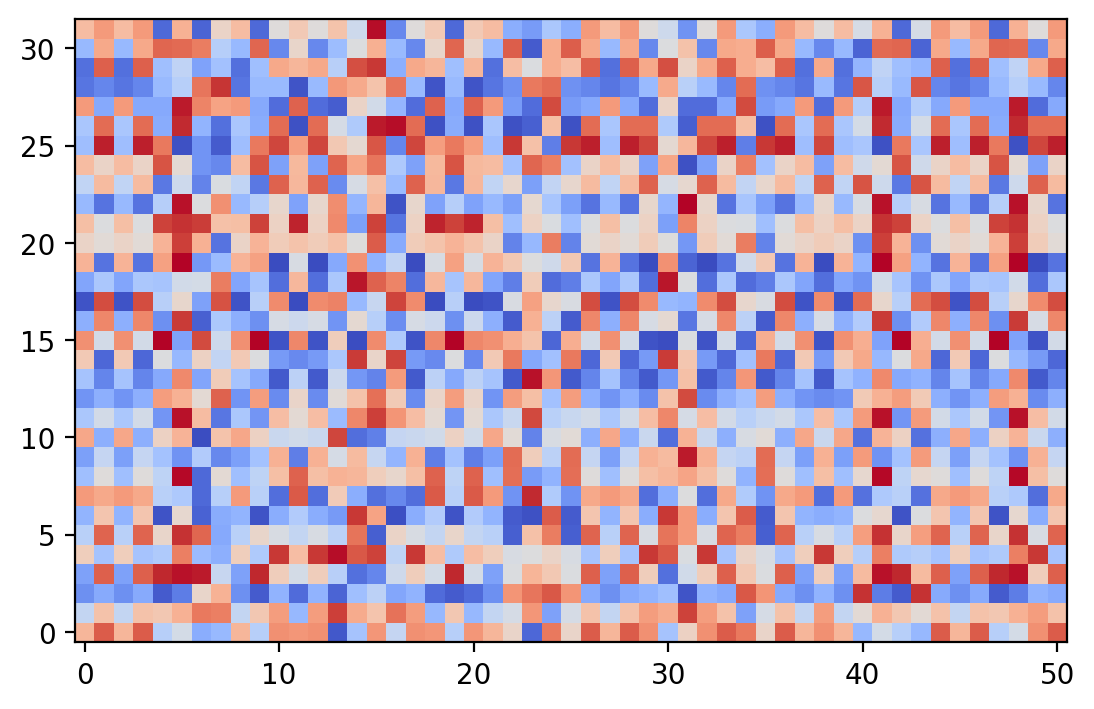

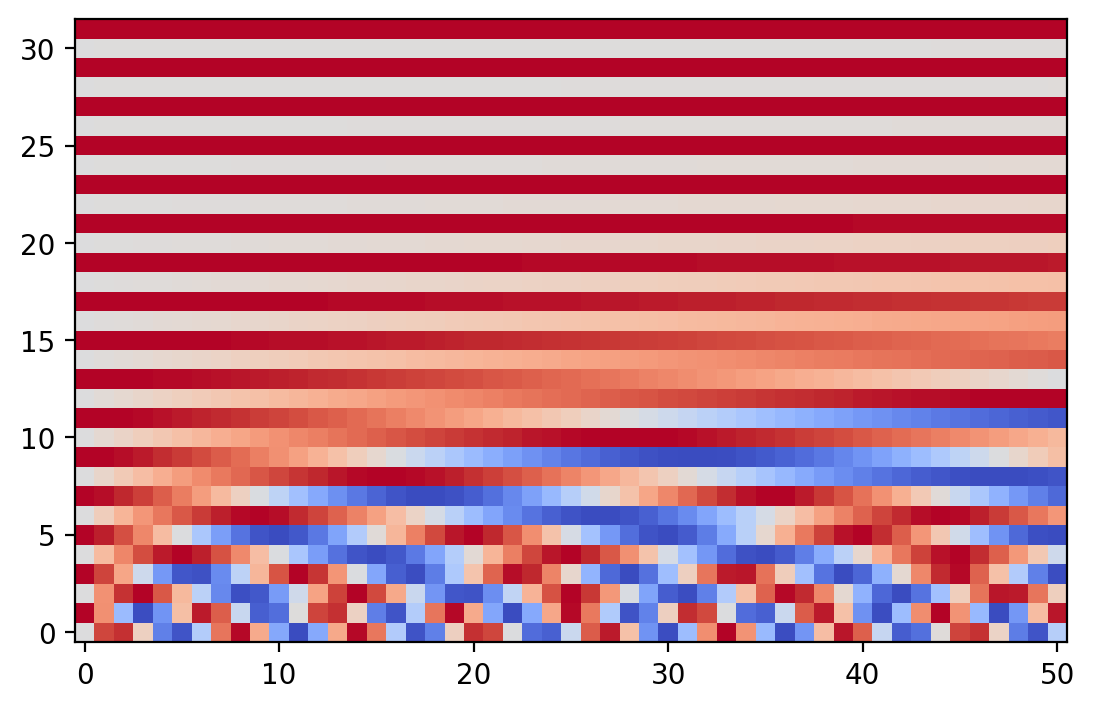

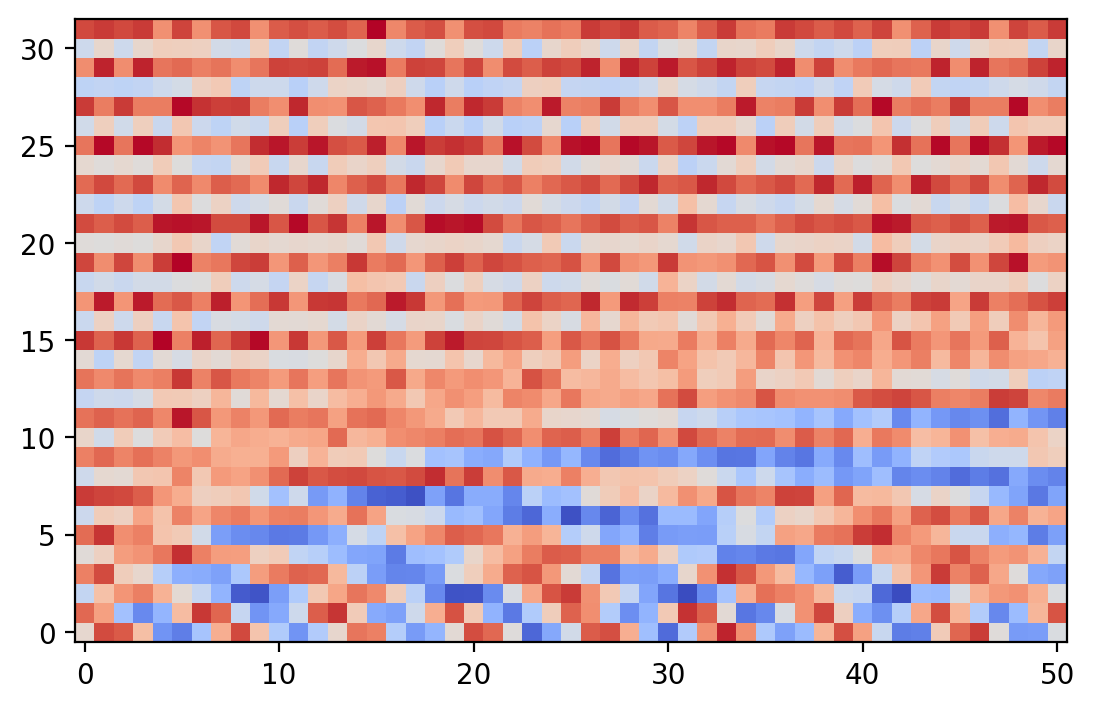

In [56]:
tpe = TokenAndPositionEmbedding(notes_vocab_size, 32)
token_embedding = tpe.token_emb(example_tokenised_notes)
position_embedding = tpe.pos_emb(token_embedding)
embedding = tpe(example_tokenised_notes)
plt.imshow(
    np.transpose(token_embedding),
    cmap="coolwarm",
    interpolation="nearest",
    origin="lower",
)
plt.show()
plt.imshow(
    np.transpose(position_embedding),
    cmap="coolwarm",
    interpolation="nearest",
    origin="lower",
)
plt.show()
plt.imshow(
    np.transpose(embedding),
    cmap="coolwarm",
    interpolation="nearest",
    origin="lower",
)
plt.show()

## 8. Build the Transformer model <a name="transformer_decoder"></a>

**Change 4.** After concatenating the note and duration embeddings, a learned Dense + LayerNorm "fusion" layer lets the model mix pitch and rhythm information before attention, instead of leaving the two halves of the vector separate. Two blocks are stacked (change 1).

**Change 9.** A Pre-LN stack never normalises the residual stream that leaves the last block, so a final LayerNorm is applied before the two output heads (part of the standard Pre-LN design of Xiong et al., 2020).

In [57]:
notes_vocab_size = len(notes_vocab)
durations_vocab_size = len(durations_vocab)

note_inputs = layers.Input(shape=(None,), dtype=tf.int32, name="note_inputs")
durations_inputs = layers.Input(shape=(None,), dtype=tf.int32, name="duration_inputs")
note_embeddings = TokenAndPositionEmbedding(
    notes_vocab_size, EMBEDDING_DIM // 2, DROPOUT_RATE, name="note_embedding"
)(note_inputs)
duration_embeddings = TokenAndPositionEmbedding(
    durations_vocab_size, EMBEDDING_DIM // 2, DROPOUT_RATE, name="duration_embedding"
)(durations_inputs)
embeddings = layers.Concatenate(name="concat")([note_embeddings, duration_embeddings])
embeddings = layers.Dense(EMBEDDING_DIM, activation="gelu", name="fusion")(embeddings)
embeddings = layers.LayerNormalization(epsilon=1e-6, name="fusion_ln")(embeddings)

x = embeddings
for b in range(N_BLOCKS):
    x, attention_scores = TransformerBlock(
        N_HEADS, KEY_DIM, EMBEDDING_DIM, FEED_FORWARD_DIM, name=f"attention_{b + 1}"
    )(x)

# Pre-LN stacks leave the residual stream un-normalised, so it is normalised once
# more before the output heads (change 9)
x = layers.LayerNormalization(epsilon=1e-6, name="final_ln")(x)

note_outputs = layers.Dense(
    notes_vocab_size, activation="softmax", name="note_outputs"
)(x)
duration_outputs = layers.Dense(
    durations_vocab_size, activation="softmax", name="duration_outputs"
)(x)
model = models.Model(
    inputs=[note_inputs, durations_inputs],
    outputs=[note_outputs, duration_outputs],
)
model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    ),
    loss=[
        losses.SparseCategoricalCrossentropy(),
        losses.SparseCategoricalCrossentropy(),
    ],
    metrics=[["accuracy"], ["accuracy"]],
)

# Same layers, extra output (last block's attention scores) used for the attention plot
att_model = models.Model(
    inputs=[note_inputs, durations_inputs],
    outputs=[note_outputs, duration_outputs, attention_scores],
)

In [58]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ note_inputs         │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duration_inputs     │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ note_embedding      │ (None, None, 64)  │      3,776 │ note_inputs[0][0] │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duration_embedding  │ (None, None, 64)  │      1,536 │ duration_inputs[… │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat              │ (None, None, 128) │          0 │ note_embedding[0… │
│ (Concatenate)       │                   │            │ duration_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion (Dense)      │ (None, None, 128) │     16,512 │ concat[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_ln           │ (None, None, 128) │        256 │ fusion[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_1         │ [(None, None,     │    198,400 │ fusion_ln[0][0]   │
│ (TransformerBlock)  │ 128), (None, 4,   │            │                   │
│                     │ None, None)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_2         │ [(None, None,     │    198,400 │ attention_1[0][0] │
│ (TransformerBlock)  │ 128), (None, 4,   │            │                   │
│                     │ None, None)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ note_outputs        │ (None, None, 59)  │      7,611 │ attention_2[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duration_outputs    │ (None, None, 24)  │      3,096 │ attention_2[0][0] │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 429,587 (1.64 MB)

 Trainable params: 429,587 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

In [59]:
if LOAD_MODEL:
    weights = os.path.join(MODELS_DIR, "transformer_modified.weights.h5")
    if os.path.exists(weights):
        model.load_weights(weights)
        print("Loaded", weights)

## 9. Train the Transformer <a name="train"></a>

**Changes 7 & 8 — the generator.** Compared with the baseline `MusicGenerator`:

* the model is wrapped in a `tf.function` with a *fixed input signature* — compiled once, no retracing, no `model.predict()` machinery;
* the attention scores come out of the **same** forward pass (the baseline ran a second model for them and rebuilt that model every call);
* temperature is applied to log-probabilities, followed by a repetition penalty (Keskar et al., 2019), top-k and nucleus filtering (Holtzman et al., 2020);
* the padding / `[UNK]` tokens are masked rather than resampled in a `while` loop;
* a pitched note can never be given a `0.0` duration, and key / time-signature tokens always get `0.0`;
* the caller's seed lists are no longer mutated.

In [60]:
class FastMusicGenerator(callbacks.Callback):
    def __init__(
        self,
        index_to_note,
        index_to_duration,
        infer_model,
        top_k=TOP_K,
        top_p=TOP_P,
        repetition_penalty=REPETITION_PENALTY,
        repetition_window=REPETITION_WINDOW,
        epoch_log_every=5,
    ):
        super().__init__()
        self.index_to_note = list(index_to_note)
        self.index_to_duration = list(index_to_duration)
        self.note_to_index = {n: i for i, n in enumerate(self.index_to_note)}
        self.duration_to_index = {d: i for i, d in enumerate(self.index_to_duration)}
        self.zero_dur_idx = self.duration_to_index.get("0.0")
        self.top_k, self.top_p = top_k, top_p
        self.repetition_penalty, self.repetition_window = (
            repetition_penalty,
            repetition_window,
        )
        self.epoch_log_every = epoch_log_every
        self.infer_model = infer_model

        # compiled once; fixed signature => never retraces for new sequence lengths
        @tf.function(
            input_signature=[
                tf.TensorSpec([1, None], tf.int32),
                tf.TensorSpec([1, None], tf.int32),
            ]
        )
        def _step(n, d):
            note_p, dur_p, att = self.infer_model([n, d], training=False)
            return note_p[0, -1], dur_p[0, -1], att[0, :, -1, :]

        self._step = _step

    # ---- sampling -----------------------------------------------------------------
    def sample_from(
        self, probs, temperature, recent=None, forbidden=(0, 1), top_k=None, top_p=None,
        penalty=None,
    ):
        top_k = self.top_k if top_k is None else top_k
        top_p = self.top_p if top_p is None else top_p
        penalty = self.repetition_penalty if penalty is None else penalty

        logits = np.log(np.clip(np.asarray(probs, dtype=np.float64), 1e-12, 1.0))
        if recent is not None and penalty > 1.0:
            for tok in set(recent[-self.repetition_window :]):
                logits[tok] = logits[tok] * penalty if logits[tok] < 0 else logits[tok] / penalty
        logits = logits / max(temperature, 1e-3)
        logits[list(forbidden)] = -np.inf
        if 0 < top_k < len(logits):
            logits[np.argsort(logits)[:-top_k]] = -np.inf
        p = np.exp(logits - logits.max())
        p /= p.sum()
        if top_p < 1.0:
            order = np.argsort(p)[::-1]
            cum = np.cumsum(p[order])
            drop = cum - p[order] >= top_p       # keep the smallest set with mass >= top_p
            p[order[drop]] = 0.0
            p /= p.sum()
        return int(np.random.choice(len(p), p=p)), p

    def get_note(self, note_dist, dur_dist, temperature, recent_notes, **kw):
        note_idx, note_probs = self.sample_from(note_dist, temperature, recent_notes, **kw)
        note = self.index_to_note[note_idx]
        is_meta = note == "START" or "TS" in note or "major" in note or "minor" in note
        if is_meta:                                # key / time signature / START: zero length
            dur_idx = self.zero_dur_idx
            dur_probs = np.eye(len(dur_dist))[dur_idx]
        else:                                      # sounding note or rest: must last > 0
            dur_idx, dur_probs = self.sample_from(
                dur_dist, temperature, None, forbidden=(0, 1, self.zero_dur_idx),
                penalty=1.0, **{k: v for k, v in kw.items() if k != "penalty"},
            )
        duration = self.index_to_duration[dur_idx]
        return get_midi_note(note, duration), note_idx, note, note_probs, dur_idx, duration, dur_probs

    # ---- generation ---------------------------------------------------------------
    def generate(self, start_notes, start_durations, max_tokens, temperature, **kw):
        start_notes, start_durations = list(start_notes), list(start_durations)
        note_tokens = [self.note_to_index.get(x, 1) for x in start_notes]
        dur_tokens = [self.duration_to_index.get(x, 1) for x in start_durations]
        info = []
        midi_stream = music21.stream.Stream()
        midi_stream.append(music21.clef.BassClef())
        for n, d in zip(start_notes, start_durations):
            m = get_midi_note(n, d)
            if m is not None:
                midi_stream.append(m)

        while len(note_tokens) < max_tokens:
            note_dist, dur_dist, att = self._step(
                tf.constant([note_tokens], tf.int32), tf.constant([dur_tokens], tf.int32)
            )
            new_note, n_idx, n_name, n_p, d_idx, d_name, d_p = self.get_note(
                note_dist.numpy(), dur_dist.numpy(), temperature, note_tokens, **kw
            )
            if new_note is not None:
                midi_stream.append(new_note)
            info.append(
                {
                    "prompt": [start_notes.copy(), start_durations.copy()],
                    "midi": midi_stream,
                    "chosen_note": (n_name, d_name),
                    "note_probs": n_p,
                    "duration_probs": d_p,
                    "atts": att.numpy(),
                }
            )
            note_tokens.append(n_idx); dur_tokens.append(d_idx)
            start_notes.append(n_name); start_durations.append(d_name)
            if n_name == "START":
                break
        return info

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % self.epoch_log_every == 0:
            info = self.generate(["START"], ["0.0"], GENERATE_LEN, 0.5)
            toks = [f"{n}:{d}" for n, d in zip(*info[-1]["prompt"])][-10:]
            print(f"\n  epoch {epoch + 1} sample ... {' '.join(toks)}")

In [61]:
# Callbacks: keep the best weights on the held-out set, stop when it stops improving
checkpoint_path = os.path.join(MODELS_DIR, "transformer_modified.weights.h5")
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    save_weights_only=True,
    save_best_only=True,
    monitor="val_loss",
    verbose=0,
)
early_stopping = callbacks.EarlyStopping(
    monitor="val_loss", patience=6, restore_best_weights=True, verbose=1
)
reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1
)

music_generator = FastMusicGenerator(notes_vocab, durations_vocab, att_model)

In [62]:
t0 = time.time()
history = model.fit(
    ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        model_checkpoint_callback,
        early_stopping,
        reduce_lr,
        music_generator,
    ],
    verbose=2,
)
train_time = time.time() - t0
print(f"Trained for {len(history.history['loss'])} epochs in {train_time / 60:.1f} min")

Epoch 1/30

  epoch 1 sample ... E-3:1.0 F3:1.0 E-3:1.0 F3:1.0 G3:1.0 B-3:1.0 G#3:1.0 G3:1.0 C4:1.0 B-3:1.0
97/97 - 28s - 288ms/step - duration_outputs_accuracy: 0.8167 - duration_outputs_loss: 0.7187 - loss: 3.7648 - note_outputs_accuracy: 0.1599 - note_outputs_loss: 3.0458 - val_duration_outputs_accuracy: 0.7819 - val_duration_outputs_loss: 1.2143 - val_loss: 3.8208 - val_note_outputs_accuracy: 0.1991 - val_note_outputs_loss: 2.7007 - learning_rate: 0.0010
Epoch 2/30
97/97 - 3s - 28ms/step - duration_outputs_accuracy: 0.8479 - duration_outputs_loss: 0.5282 - loss: 2.9906 - note_outputs_accuracy: 0.2556 - note_outputs_loss: 2.4623 - val_duration_outputs_accuracy: 0.7815 - val_duration_outputs_loss: 0.9933 - val_loss: 3.5216 - val_note_outputs_accuracy: 0.2308 - val_note_outputs_loss: 2.6064 - learning_rate: 0.0010
Epoch 3/30
97/97 - 3s - 28ms/step - duration_outputs_accuracy: 0.8531 - duration_outputs_loss: 0.4925 - loss: 2.7775 - note_outputs_accuracy: 0.2862 - note_outputs_loss: 2.2

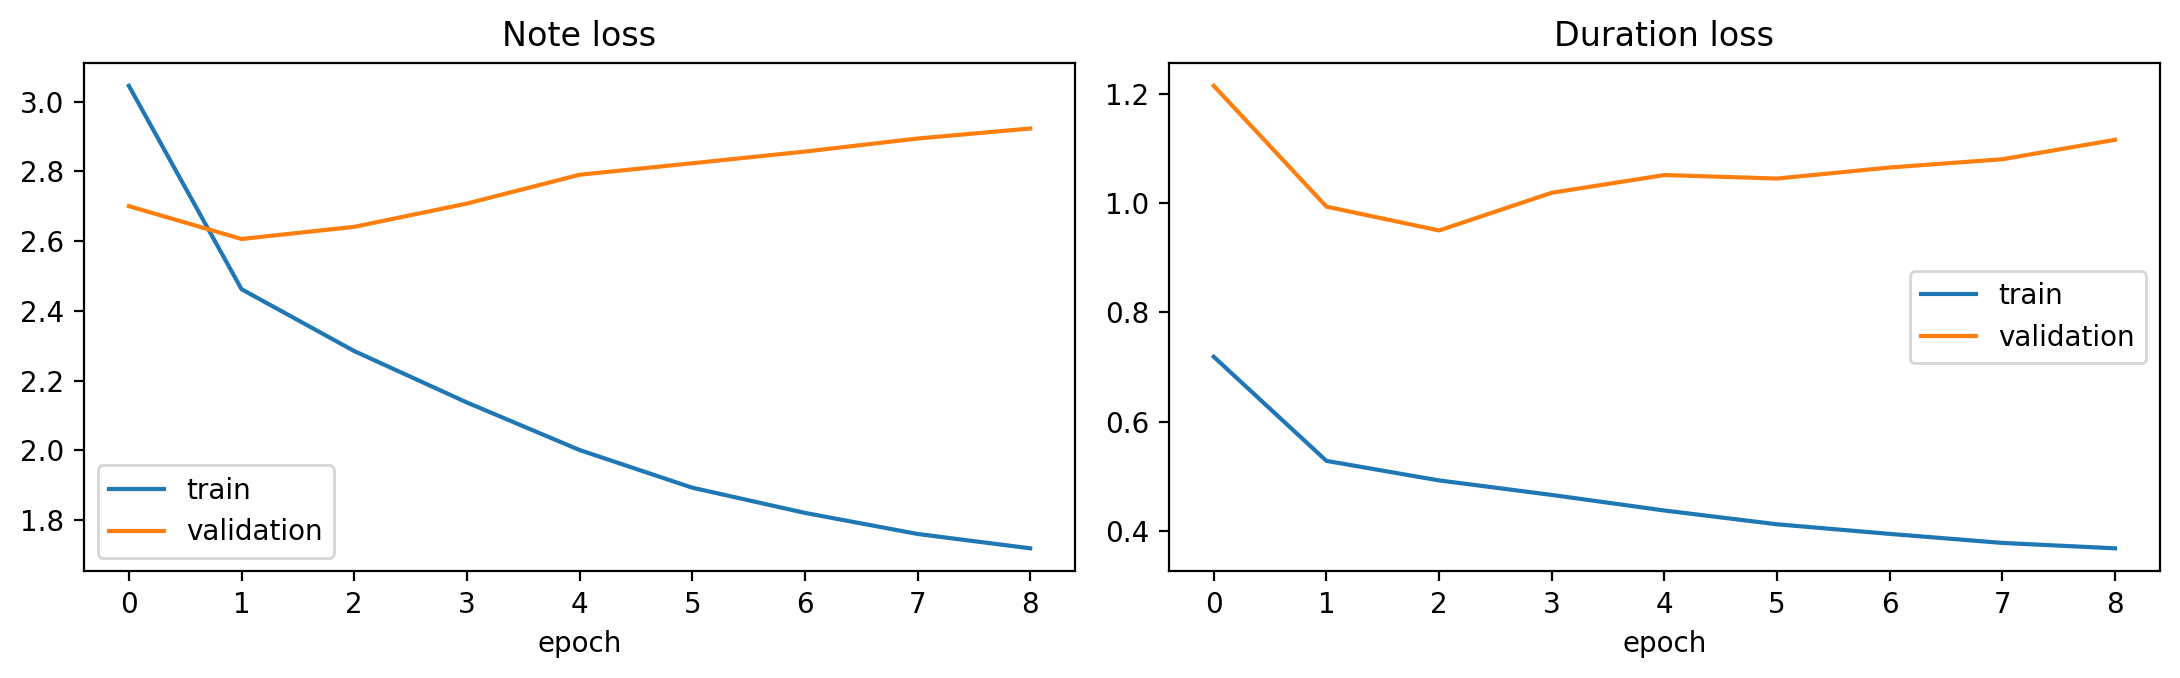

Held-out (unseen movements) results:
  duration_outputs_accuracy    0.7874
  duration_outputs_loss        0.9497
  loss                         3.5095
  note_outputs_accuracy        0.2359
  note_outputs_loss            2.6413


In [63]:
# Weights of the best epoch were restored by EarlyStopping; keep them on disk
model.save_weights(checkpoint_path)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
h = history.history
axes[0].plot(h["note_outputs_loss"], label="train"); axes[0].plot(h["val_note_outputs_loss"], label="validation")
axes[0].set_title("Note loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h["duration_outputs_loss"], label="train"); axes[1].plot(h["val_duration_outputs_loss"], label="validation")
axes[1].set_title("Duration loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "modified_training_curves.png"), dpi=150); plt.show()

val_result = model.evaluate(val_ds, verbose=0, return_dict=True)
print("Held-out (unseen movements) results:")
for k, v in val_result.items():
    print(f"  {k:28s} {v:.4f}")

# 3. Inference speed

One forward pass on a 4-token prompt, averaged over 50 calls (after warm-up). `model.predict()` is what the baseline's generation loop used (and it called it **twice** per token — once for the probabilities and once more through a freshly built attention model).

In [64]:
n_t = tf.constant([[2, 3, 4, 5]], tf.int32)
d_t = tf.constant([[9, 2, 2, 2]], tf.int32)
for _ in range(3):  # warm-up
    music_generator._step(n_t, d_t); model.predict([n_t.numpy(), d_t.numpy()], verbose=0)

R = 50
t0 = time.perf_counter()
for _ in range(R):
    model.predict([n_t.numpy(), d_t.numpy()], verbose=0)
ms_predict = (time.perf_counter() - t0) / R * 1000
t0 = time.perf_counter()
for _ in range(R):
    music_generator._step(n_t, d_t)[0].numpy()
ms_fast = (time.perf_counter() - t0) / R * 1000
print(f"model.predict():      {ms_predict:7.2f} ms / forward pass")
print(f"compiled tf.function: {ms_fast:7.2f} ms / forward pass  ({ms_predict / ms_fast:.1f}x faster)")

model.predict():        75.39 ms / forward pass
compiled tf.function:    3.10 ms / forward pass  (24.4x faster)


# 4. Generate music using the Transformer

We seed the network with the `START` note token and the `0.0` duration token.

In [65]:
np.random.seed(7)
info = music_generator.generate(["START"], ["0.0"], max_tokens=GENERATE_LEN, temperature=0.5)
midi_stream = info[-1]["midi"].chordify()
try:
    midi_stream.show()
except Exception as e:
    print(f"Graphical sheet music viewer not available ({e}). Showing as text:")
    midi_stream.show("text")

Graphical sheet music viewer not available (Cannot find a path to the 'mscore' file at /usr/bin/mscore3 -- download MuseScore). Showing as text:
{0.0} <music21.clef.BassClef>
{0.0} <music21.meter.TimeSignature 3/4>
{0.0} <music21.note.Rest dotted-eighth>
{0.75} <music21.chord.Chord D3>
{1.0} <music21.chord.Chord C3>
{1.25} <music21.chord.Chord D3>
{1.5} <music21.chord.Chord C3>
{1.75} <music21.chord.Chord D3>
{2.0} <music21.chord.Chord E-3>
{2.25} <music21.chord.Chord F3>
{2.5} <music21.chord.Chord G3>
{3.25} <music21.chord.Chord F3>
{3.5} <music21.chord.Chord E-3>
{3.75} <music21.chord.Chord D3>
{4.0} <music21.chord.Chord E-3>
{4.25} <music21.chord.Chord D3>
{4.5} <music21.chord.Chord C3>
{4.75} <music21.chord.Chord D3>
{5.0} <music21.chord.Chord C3>
{5.25} <music21.chord.Chord B-2>
{5.5} <music21.chord.Chord C3>
{5.75} <music21.chord.Chord D3>
{6.0} <music21.chord.Chord E-3>
{6.25} <music21.chord.Chord D3>
{6.5} <music21.chord.Chord C3>
{6.75} <music21.chord.Chord B-2>
{7.0} <music21

## Write music to MIDI file

In [66]:
timestr = time.strftime("%Y%m%d-%H%M%S")
midi_stream.write("midi", fp=os.path.join(OUTPUT_DIR, "modified-output-" + timestr + ".mid"))
midi_stream.write("midi", fp=os.path.join(OUTPUT_DIR, "modified_example.mid"))
print("generated:", " ".join(f"{n}:{d}" for n, d in zip(*info[-1]["prompt"])))

generated: START:0.0 3/4TS:0.0 rest:0.75 D3:0.25 C3:0.25 D3:0.25 C3:0.25 D3:0.25 E-3:0.25 F3:0.25 G3:0.75 F3:0.25 E-3:0.25 D3:0.25 E-3:0.25 D3:0.25 C3:0.25 D3:0.25 C3:0.25 B-2:0.25 C3:0.25 D3:0.25 E-3:0.25 D3:0.25 C3:0.25 B-2:0.25 G#2:0.25 G2:0.25 F2:0.25 D3:0.25 E-3:0.25 F3:0.25 G3:0.25 F3:0.25 G3:0.25 G#3:0.25 G3:0.25 F3:0.25 E-3:0.25 D3:0.25 E-3:0.25 D3:0.25 E-3:0.25 F3:0.25 G3:0.25 G#3:0.25 B-3:0.25 G#3:0.25 G3:0.25


### Choosing your own seed

Any (note, duration) tokens can seed the model. Here we start on the Suite No. 1 arpeggio `G2 D3 B3` (sixteenth notes), and on the D-minor `D3 F3 A3` of Suite No. 2.

In [67]:
seeds = {
    "seed_G2_D3_B3": (["START", "G2", "D3", "B3"], ["0.0", "0.25", "0.25", "0.25"]),
    "seed_D3_F3_A3": (["START", "D3", "F3", "A3"], ["0.0", "0.25", "0.25", "0.25"]),
}
np.random.seed(11)
for name, (sn, sd) in seeds.items():
    inf = music_generator.generate(sn, sd, max_tokens=GENERATE_LEN, temperature=0.7)
    inf[-1]["midi"].chordify().write("midi", fp=os.path.join(OUTPUT_DIR, f"modified_{name}.mid"))
    print(name, "->", " ".join(f"{n}:{d}" for n, d in zip(*inf[-1]["prompt"]))[:400], "\n")

seed_G2_D3_B3 -> START:0.0 G2:0.25 D3:0.25 B3:0.25 A3:0.25 B3:0.25 A3:0.25 G3:0.25 F#3:0.25 D3:0.25 G2:0.25 D3:0.25 G3:0.25 A3:0.25 B3:0.25 A3:0.25 G3:0.25 F#3:0.25 G3:0.25 D3:0.25 C3:0.25 B2:0.25 A2:0.25 G2:0.25 D3:0.25 D3:0.25 D3:0.25 G2:0.25 A2:0.25 G2:0.25 D3:0.25 G2:0.25 G3:0.25 F3:0.25 E3:0.25 F3:0.25 E3:0.25 F3:0.25 E3:0.25 F3:0.25 G2:0.25 B3:0.25 C4:0.25 A3:0.25 C4:0.25 B3:0.25 C4:0.25 B3:0.25 C4:0.25 

seed_D3_F3_A3 -> START:0.0 D3:0.25 F3:0.25 A3:0.25 D3:0.25 F3:0.25 D3:0.25 C3:0.25 D3:0.25 C3:0.25 D3:0.25 E-3:0.25 D3:0.25 C3:0.25 D3:0.25 C3:0.25 D3:0.25 C3:0.25 D3:0.25 C3:0.25 D3:0.25 C3:0.25 B-2:0.25 A2:0.25 G2:0.25 F2:0.25 E2:0.25 G2:0.25 F2:0.25 E2:0.25 F2:0.25 E2:0.25 C3:0.25 B-2:0.25 C3:0.25 G2:0.25 F2:0.25 G2:0.25 D3:0.25 G2:0.25 F3:0.25 G2:0.25 F2:0.25 G2:0.25 F2:0.25 G2:0.25 G#2:0.25 G2:0.25 F3:0.25 



## Note probabilities

In [68]:
max_pitch = 70
seq_len = len(info)
grid = np.zeros((max_pitch, seq_len), dtype=np.float32)

for j in range(seq_len):
    for i, prob in enumerate(info[j]["note_probs"]):
        try:
            pitch = music21.note.Note(notes_vocab[i]).pitch.midi
            grid[pitch, j] = prob
        except Exception:
            pass  # Don't show key / time signatures

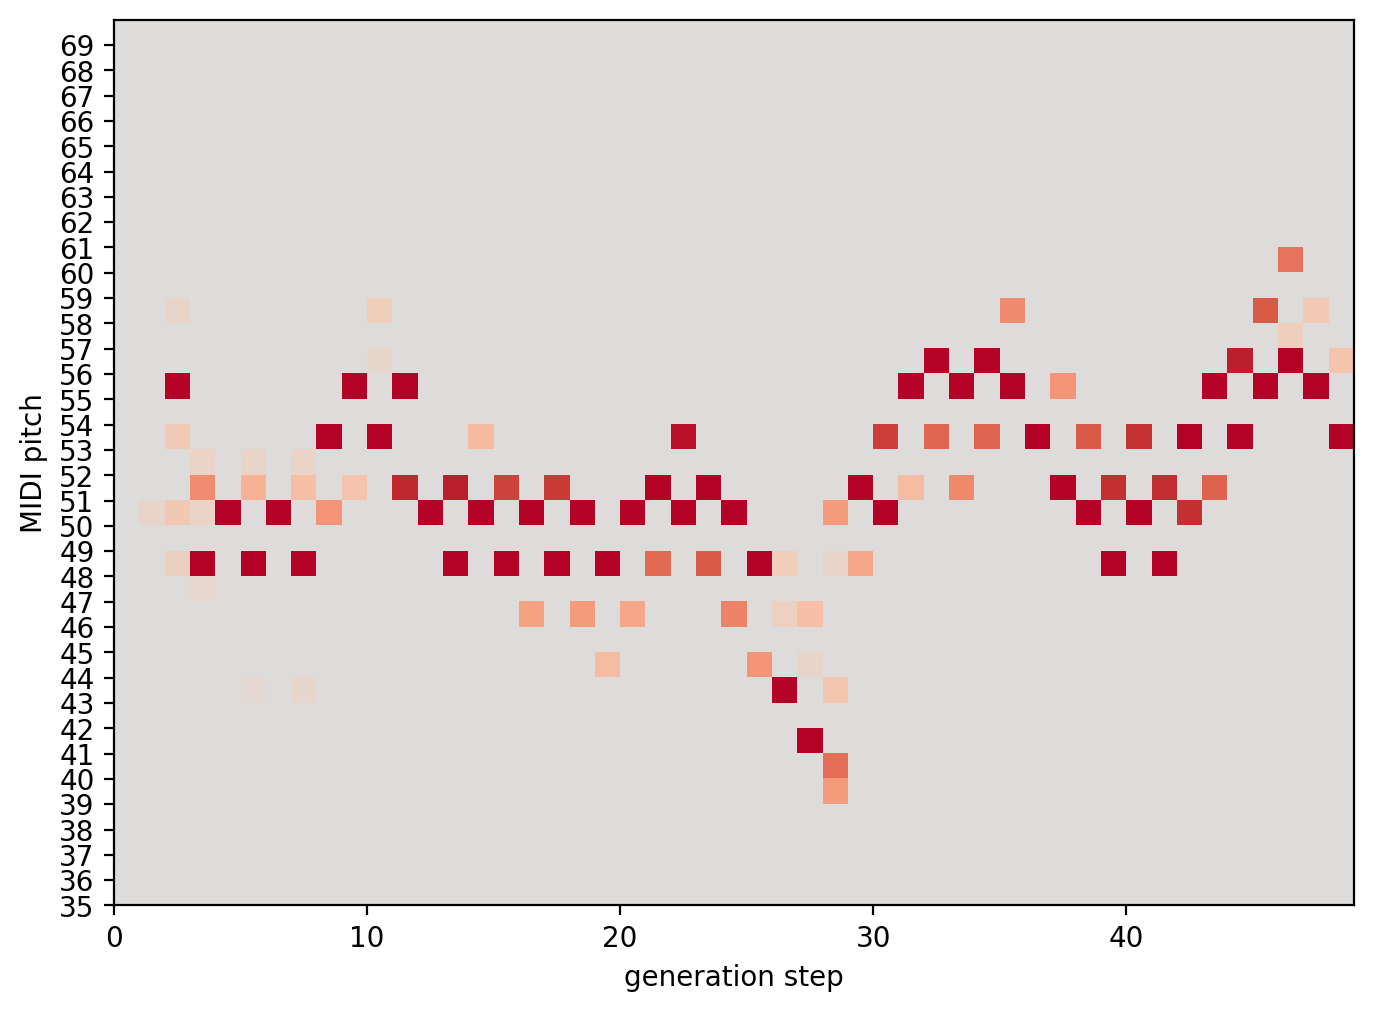

In [69]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_yticks([int(j) for j in range(35, 70)])
plt.imshow(grid[35:70, :], origin="lower", cmap="coolwarm", vmin=-0.5, vmax=0.5,
           extent=[0, seq_len, 35, 70])
plt.xlabel("generation step"); plt.ylabel("MIDI pitch")
plt.savefig(os.path.join(OUTPUT_DIR, "modified_note_probabilities.png"), dpi=150)
plt.show()

## Attention Plot

In [70]:
plot_size = 20

att_matrix = np.zeros((plot_size, plot_size))
prediction_output = []
last_prompt = []

In [71]:
for j in range(plot_size):
    atts = info[j]["atts"].max(axis=0)
    att_matrix[: (j + 1), j] = atts
    prediction_output.append(info[j]["chosen_note"][0])
    last_prompt.append(info[j]["prompt"][0][-1])

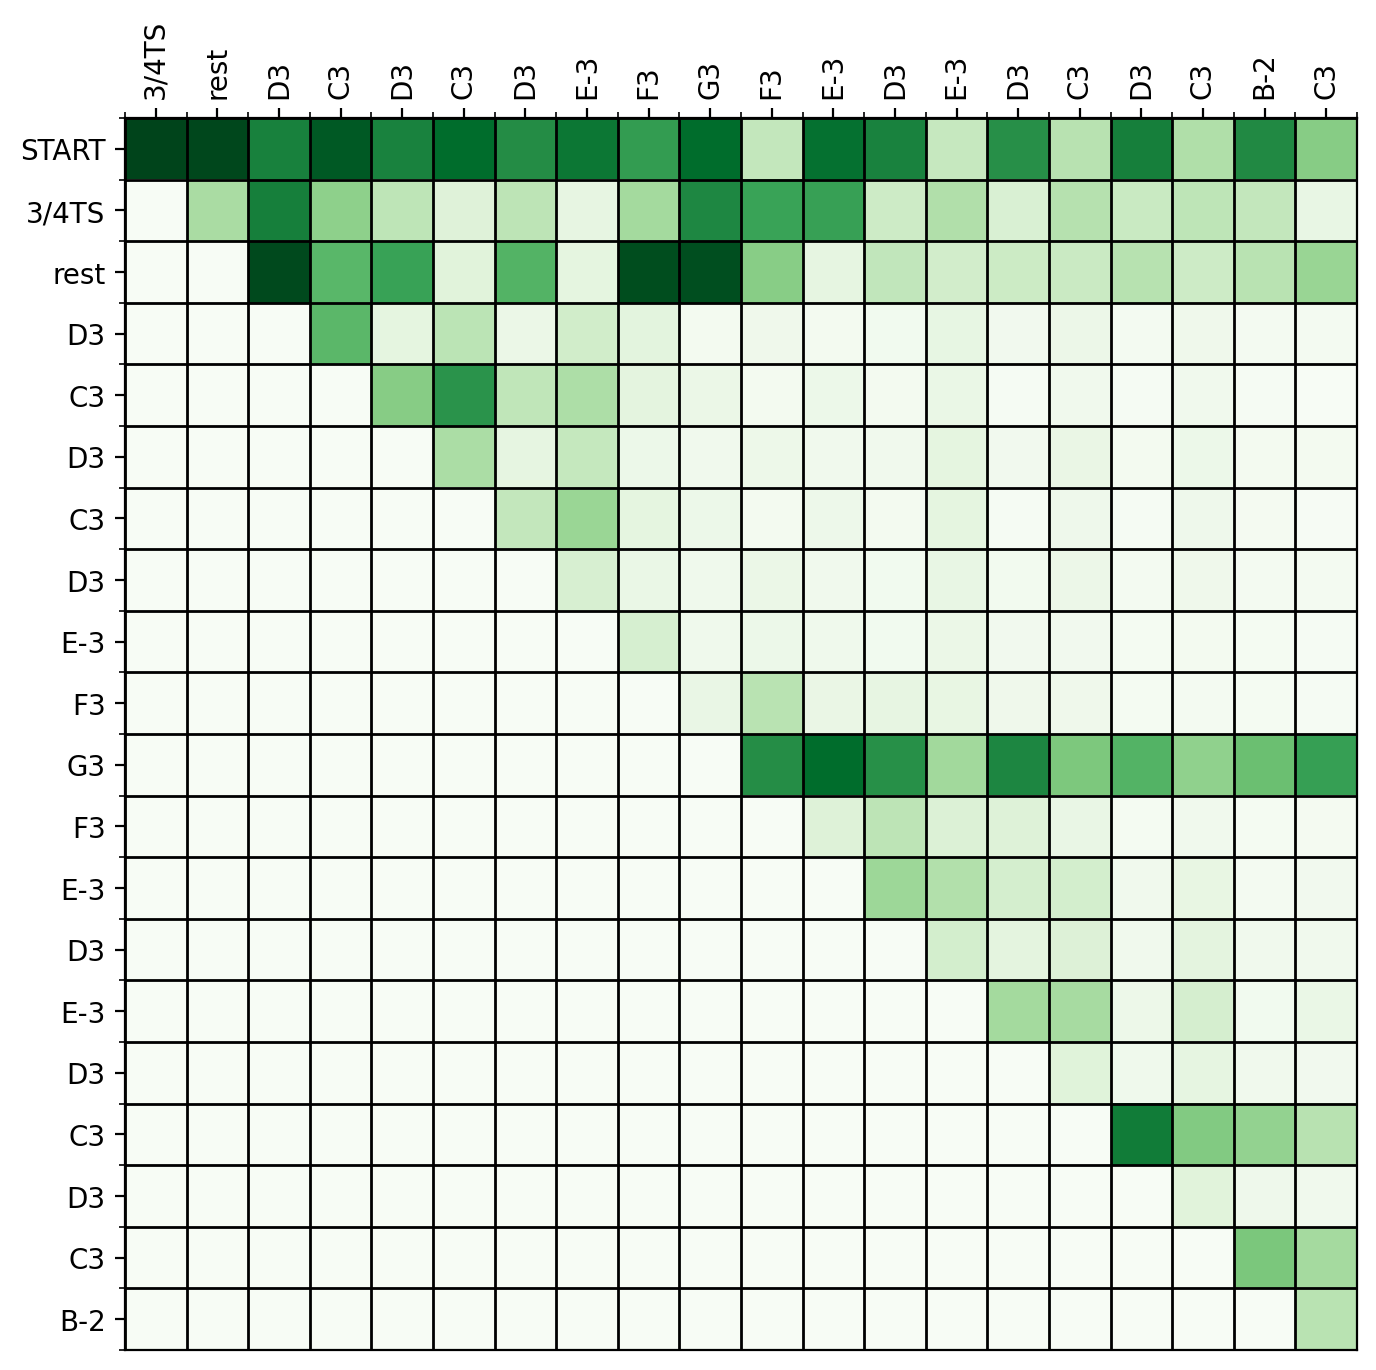

In [72]:
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(att_matrix, cmap="Greens", interpolation="nearest")

ax.set_xticks(np.arange(-0.5, plot_size, 1), minor=True)
ax.set_yticks(np.arange(-0.5, plot_size, 1), minor=True)
ax.grid(which="minor", color="black", linestyle="-", linewidth=1)
ax.set_xticks(np.arange(plot_size))
ax.set_yticks(np.arange(plot_size))
ax.set_xticklabels(prediction_output[:plot_size])
ax.set_yticklabels(last_prompt[:plot_size])
ax.xaxis.tick_top()

plt.setp(ax.get_xticklabels(), rotation=90, ha="left", va="center", rotation_mode="anchor")
plt.savefig(os.path.join(OUTPUT_DIR, "modified_attention_map.png"), dpi=150, bbox_inches="tight")
plt.show()

# 5. Quantitative evaluation of generated music

We draw 20 independent 50-token pieces from `START` and compute simple quality statistics (`generation_metrics` in `transformer_utils.py`): number of distinct notes, repeated-trigram rate, longest run of one identical note, and the share of the most frequent note. The same statistics, computed on real Bach windows from the held-out movements, are the reference. `baseline_benchmark.py` runs exactly the same protocol on the original architecture and sampler.

Rows: **A** = modified model with *plain* temperature sampling (isolates the effect of architecture/training); **B** = modified model with the full decoder (top-k, top-p, repetition penalty).

In [73]:
N_SAMPLES = 20


def run_samples(temperature, seed, **kw):
    np.random.seed(seed)
    gn, gd, per_tok = [], [], []
    for _ in range(N_SAMPLES):
        t0 = time.perf_counter()
        inf = music_generator.generate(["START"], ["0.0"], GENERATE_LEN, temperature, **kw)
        per_tok.append((time.perf_counter() - t0) / len(inf) * 1000)
        gn.append([s["chosen_note"][0] for s in inf])
        gd.append([s["chosen_note"][1] for s in inf])
    return {
        "temperature": temperature,
        "ms_per_token_mean": float(np.mean(per_tok)),
        "ms_per_token_std": float(np.std(per_tok)),
        "metrics": generation_metrics(gn, gd),
    }


plain = dict(top_k=0, top_p=1.0, penalty=1.0)
gen_results = {
    "A_plain_T0.5": run_samples(0.5, 0, **plain),
    "B_full_T0.3": run_samples(0.3, 0),
    "B_full_T0.5": run_samples(0.5, 0),
    "B_full_T0.7": run_samples(0.7, 0),
    "B_full_T1.2": run_samples(1.2, 0),
}
rs = np.random.RandomState(0).choice(len(val_note_ids), N_SAMPLES, replace=False)
real = generation_metrics(
    [[notes_vocab[t] for t in val_note_ids[i][:50]] for i in rs],
    [[durations_vocab[t] for t in val_dur_ids[i][:50]] for i in rs],
)

cols = ["unique_notes", "rep_trigram_rate", "longest_run", "top_token_share"]
print(f"{'setting':16s} {'ms/token':>9s} " + " ".join(f"{c:>17s}" for c in cols))
for k, v in gen_results.items():
    print(f"{k:16s} {v['ms_per_token_mean']:9.2f} " + " ".join(f"{v['metrics'][c]['mean']:17.3f}" for c in cols))
print(f"{'real Bach':16s} {'':>9s} " + " ".join(f"{real[c]['mean']:17.3f}" for c in cols))

setting           ms/token      unique_notes  rep_trigram_rate       longest_run   top_token_share
A_plain_T0.5          3.91            12.250             0.307             1.850             0.270
B_full_T0.3           4.04             9.300             0.582             1.750             0.389
B_full_T0.5           4.27            11.800             0.349             1.200             0.268
B_full_T0.7           4.20            13.950             0.217             1.650             0.214
B_full_T1.2           4.18            16.300             0.056             1.850             0.173
real Bach                             15.650             0.109             2.450             0.167


In [74]:
out = {
    "config": dict(EMBEDDING_DIM=EMBEDDING_DIM, KEY_DIM=KEY_DIM, N_HEADS=N_HEADS, N_BLOCKS=N_BLOCKS,
                   DROPOUT_RATE=DROPOUT_RATE, FEED_FORWARD_DIM=FEED_FORWARD_DIM, BATCH_SIZE=BATCH_SIZE,
                   LEARNING_RATE=LEARNING_RATE, WEIGHT_DECAY=WEIGHT_DECAY, TOP_K=TOP_K, TOP_P=TOP_P,
                   REPETITION_PENALTY=REPETITION_PENALTY, AUGMENT=AUGMENT,
                   TRANSPOSE_SHIFTS=[min(TRANSPOSE_SHIFTS), max(TRANSPOSE_SHIFTS)]),
    "params": int(model.count_params()),
    "n_train_sequences": int(len(train_note_ids)), "n_val_sequences": int(len(val_note_ids)),
    "notes_vocab": notes_vocab_size, "durations_vocab": durations_vocab_size,
    "epochs_run": len(history.history["loss"]), "train_time_s": train_time,
    "train_last": {k: float(v[-1]) for k, v in history.history.items()},
    "val_eval": {k: float(v) for k, v in val_result.items()},
    "history": {k: [float(x) for x in v] for k, v in history.history.items()},
    "forward_pass_ms": {"predict": ms_predict, "tf_function": ms_fast},
    "generation": gen_results,
    "real_bach_reference": real,
}
with open(os.path.join(OUTPUT_DIR, "modified_metrics.json"), "w") as f:
    json.dump(out, f, indent=2)
print("saved output/modified_metrics.json")

saved output/modified_metrics.json
